# EJEMPLO MASA RESORTE AMORTIGUADOR
En este ejemplo se aplica el EKF para estimar las constantes del amortiguador ($b$) y del resorte ($k$)

El vector de estados es una versión extendida que incorpora los parámetros a estimar

$x_k = \begin{bmatrix}
p_k\\
v_k\\
k_k\\
b_k
\end{bmatrix}$

## Modelo de transición
El modelo es no lineal y también se implementa el Jacobiano

In [634]:
import numpy as np

def Fx(x_k, m , u_k, Ts):
    x_k1 = np.zeros(len(x_k))

    x_k1[0] = x_k[0] + x_k[1] * Ts
    x_k1[1] = x_k[1] + Ts*((-x_k[2]*x_k[0] -x_k[3]*x_k[1] + u_k)/m)
    x_k1[2] = x_k[2]
    x_k1[3] = x_k[3]

    return x_k1

# Jacobiano
def J_Fx(x_k, m, Ts):
    J = np.array([
        [1.0, Ts, 0.0, 0.0],
        [-Ts*x_k[2]/m, 1.0 - Ts*x_k[3]/m, -Ts*x_k[0]/m, -Ts*x_k[1]/m],
        [0.0, 0.0, 1.0, 0.0],
        [0.0, 0.0, 0.0, 1.0]
    ])

    return J

## Modelo de observación
Se tiene un sensor de posición de la masa.

In [635]:
def Hx(x_k):
    return x_k[0]

Simulación para generar datos

In [636]:
Tf = 60
dt = 0.01
t = np.arange(0,Tf,dt)

# valores reales
b_r = 0.5
k_r = 2.5

m = 1.0

# condiciones iniciales
x_0 = np.array([0.0, 0.0, k_r, b_r])

# Señal de entrada al sistema
Ft = np.sin(0.5*t) + 0.5*np.cos(0.9*t)

x_kreal = np.zeros((len(t), len(x_0)))
x_kreal[0] = x_0
for k in range(len(t)-1):
    x_kreal[k+1] = Fx(x_kreal[k], m, Ft[k], dt)

# mediciones con ruido
sigma_v = 0.1
z_k = x_kreal[:, 0] + sigma_v*np.random.randn(len(t))

## Mostrando resultados de la simulación
Se grafica la respuesta del sistema en posición y velocidad. Idealmente sin ruido

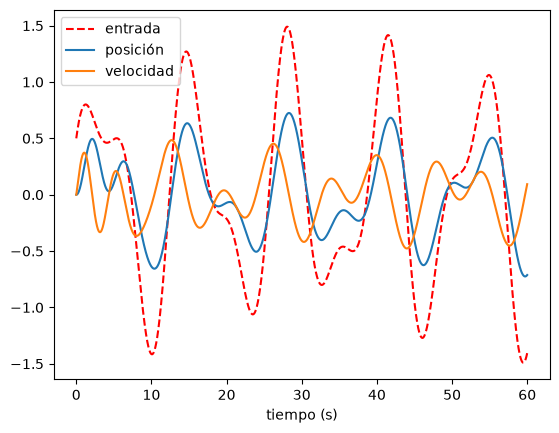

In [637]:
## graficas
import matplotlib.pyplot as plt

plt.figure(1)
plt.plot(t,Ft, label="entrada", color = 'r', linestyle='--')
plt.xlabel("tiempo (s)")

plt.plot(t,x_kreal[:, 0], label="posición" )
plt.plot(t,x_kreal[:, 1], label="velocidad")
plt.legend()

plt.show()

## Inicialización del EKF

In [638]:
# Matrices de covarianza
R = sigma_v ** 2
Q = np.identity(len(x_0)) * 1e-4

P = np.identity(len(x_0)) * 0.1
H = np.array([1.0, 0.0, 0.0, 0.0])

# Almacenamiento
x_k = np.zeros(x_kreal.shape)

## Filtro Extendido de Kalman para estimación
El modelo de transición es no lineal y SI se requiere el Jacobiano

El modelo de observación es lineal y NO se requiere el Jacobiano

Valor final k:  2.462220037328814  Error:  0.037779962671185885
Valor final b:  0.4977481363212158  Error:  0.002251863678784216


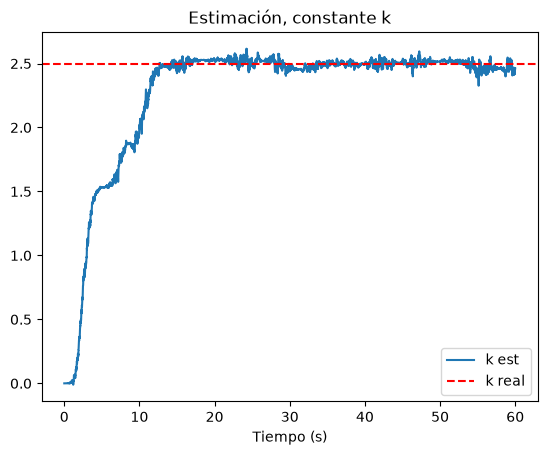

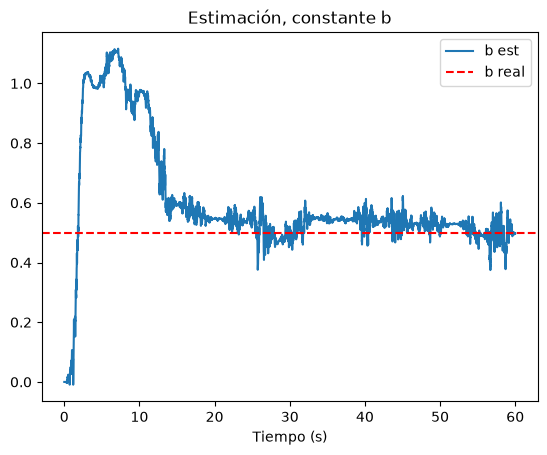

In [639]:
for k in range(len(t)-1):
    # Predicción
    x_k[k+1] = Fx(x_k[k], m, Ft[k], dt)
    F = J_Fx(x_k[k], m, dt)
    P = (F @ P) @ F.T + Q
    
    # Actualización
    y_m = z_k[k+1] - Hx(x_k[k+1])

    S = (H @ P) @ H + R
    K = (P @ H) / S
    x_k[k+1] = x_k[k+1] + K*y_m

    I = np.identity(len(x_0))
    P = (I - np.outer(K,H)) @ P

# Graficas - resultados
print("Valor final k: ", x_k[-1, 2], " Error: ", np.abs(k_r - x_k[-1, 2]))
print("Valor final b: ", x_k[-1, 3], " Error: ", np.abs(b_r - x_k[-1, 3]))

plt.figure()
plt.plot(t,x_k[:, 2], label="k est")
plt.axhline(k_r, label="k real", linestyle="--", color='r')
plt.xlabel("Tiempo (s)")
plt.title("Estimación, constante k")
plt.legend()

plt.figure()
plt.plot(t,x_k[:, 3], label="b est")
plt.axhline(b_r, label="b real", linestyle="--", color='r')
plt.xlabel("Tiempo (s)")
plt.title("Estimación, constante b")
plt.legend()

plt.show()